# Assignment 2

---

# Part 1 

Part 1: CIFAR-10 CNN

This notebook is organized according to the three-stage research flow used in the experiment.

**Run order:**
1. Run **Cell 0 — Setup** first. This cell defines the imports, CUDA device, data loading utilities, model class, training functions, and shared helper functions.
2. Run each stage separately depending on the experiment you want to reproduce.

The notebook is intentionally split into clear blocks so the grader can follow the logic of the investigation: architecture screening, focused hyperparameter search, and final generalization improvement.

## Cell 0 — Setup: imports, CUDA check, data utilities, model, and training helpers

This cell prepares everything needed by the three experimental stages. It does **not** run any experiment by itself.

It includes:
- package imports and reproducibility settings;
- CUDA/device verification;
- CIFAR-10 train/validation/test loading;
- stratified train/validation split;
- training and evaluation functions;
- the flexible CNN implementation;
- shared helper functions for creating DataLoaders, running experiments, and printing summaries.

The cell is designed to stop immediately if CUDA is not available, so the notebook will not accidentally run the experiments on CPU.

In [2]:
# ============================================================
# Assignment 2 - Part 1: CIFAR-10 CNN Multi-Stage Investigation
# Setup Cell
# ============================================================
# This cell prepares the full environment for running Stage 1, Stage 2,
# and Stage 3 in separate notebook cells.
#
# Important:
# This cell does not run any experiment.
# It only defines imports, reproducibility settings, device, data loading,
# training/evaluation functions, the CNN model, and helper functions.
# ============================================================


# ============================================================
# Imports
# ============================================================

import random
import copy
import numpy as np

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset

from torchvision import datasets, transforms

import matplotlib.pyplot as plt

try:
    from tqdm import tqdm
except ImportError:
    tqdm = None

from itertools import product


# ============================================================
# Reproducibility and device setup
# ============================================================

SEED = 42


def set_seed(seed=SEED):
    """
    Set random seeds for reproducibility.
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA is not available in this notebook kernel. "
        "Make sure VS Code is connected to the GPU host and uses the neuro_dl kernel."
    )

device = torch.device("cuda:0")

print("Using device:", device)
print("GPU:", torch.cuda.get_device_name(0))


# ============================================================
# Jupyter-friendly DataLoader settings
# ============================================================
# num_workers=0 is safer in VS Code/Jupyter on a remote cluster.
# It prevents kernel crashes caused by multiprocessing in notebook sessions.

NUM_WORKERS = 0
USE_TQDM_PROGRESS_BAR = False

print("DataLoader num_workers:", NUM_WORKERS)
print("Progress bar enabled:", USE_TQDM_PROGRESS_BAR)


# ============================================================
# Weight initialization
# ============================================================

def initialize_weights(model):
    """
    Initialize Conv2d and Linear layers using Kaiming initialization.
    This is suitable for networks that use ReLU activations.
    """
    for module in model.modules():

        if isinstance(module, nn.Conv2d):
            nn.init.kaiming_normal_(
                module.weight,
                mode="fan_out",
                nonlinearity="relu"
            )

            if module.bias is not None:
                nn.init.zeros_(module.bias)

        elif isinstance(module, nn.Linear):
            nn.init.kaiming_normal_(
                module.weight,
                nonlinearity="relu"
            )

            if module.bias is not None:
                nn.init.zeros_(module.bias)


# ============================================================
# Data loading and stratified train-validation split
# ============================================================

def create_stratified_train_val_indices(
    labels,
    validation_size=5000,
    num_classes=10,
    seed=SEED
):
    """
    Create a fixed stratified train-validation split.

    Stratified means that each class contributes the same number of samples
    to the validation set. For CIFAR-10 with validation_size=5000,
    this gives 500 validation images per class.
    """

    labels = np.array(labels)
    rng = np.random.default_rng(seed)

    train_indices = []
    val_indices = []

    val_per_class = validation_size // num_classes

    for class_idx in range(num_classes):
        class_indices = np.where(labels == class_idx)[0]
        rng.shuffle(class_indices)

        val_indices.extend(class_indices[:val_per_class])
        train_indices.extend(class_indices[val_per_class:])

    rng.shuffle(train_indices)
    rng.shuffle(val_indices)

    return train_indices, val_indices


def get_train_val_test_data(
    validation_size=5000,
    train_transforms=transforms.ToTensor(),
    test_transforms=transforms.ToTensor()
):
    """
    Load CIFAR-10 and split the official training set into:
    - training set
    - validation set

    The official CIFAR-10 test set is kept separate and is used only
    for final model evaluation.
    """

    data_root = "./data"

    full_train_dataset = datasets.CIFAR10(
        root=data_root,
        train=True,
        download=True,
        transform=train_transforms
    )

    full_val_dataset = datasets.CIFAR10(
        root=data_root,
        train=True,
        download=True,
        transform=test_transforms
    )

    test_dataset = datasets.CIFAR10(
        root=data_root,
        train=False,
        download=True,
        transform=test_transforms
    )

    train_indices, val_indices = create_stratified_train_val_indices(
        labels=full_train_dataset.targets,
        validation_size=validation_size,
        num_classes=10,
        seed=SEED
    )

    train_dataset = Subset(full_train_dataset, train_indices)
    val_dataset = Subset(full_val_dataset, val_indices)

    return train_dataset, val_dataset, test_dataset


# ============================================================
# Training and evaluation functions
# ============================================================

def train(
    model,
    optimizer,
    loss_fn,
    train_loader,
    val_loader=None,
    epochs=10,
    device=device,
    scheduler=None
):
    """
    Train a CNN model and optionally evaluate it on validation data.

    Returns:
        history: Dictionary containing training and validation metrics,
        including the best validation checkpoint.
    """

    model = model.to(device)

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    best_val_acc = -1.0
    best_val_loss = None
    best_epoch = None
    best_model_state_dict = None

    for epoch in range(epochs):

        model.train()

        total_loss = 0.0
        correct = 0
        total = 0

        if tqdm is not None and USE_TQDM_PROGRESS_BAR:
            train_iterator = tqdm(
                train_loader,
                desc=f"Epoch {epoch + 1}/{epochs}",
                leave=False
            )
        else:
            train_iterator = train_loader

        for X, y in train_iterator:

            X = X.to(device)
            y = y.to(device)

            optimizer.zero_grad()

            y_pred = model(X)
            loss = loss_fn(y_pred, y)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * X.size(0)

            predicted_classes = y_pred.argmax(dim=1)
            correct += (predicted_classes == y).sum().item()
            total += y.size(0)

        train_loss = total_loss / total
        train_acc = correct / total

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)

        if val_loader is not None:

            val_loss, val_acc = test(
                model=model,
                test_loader=val_loader,
                loss_fn=loss_fn,
                device=device
            )

            history["val_loss"].append(val_loss)
            history["val_acc"].append(val_acc)

            if val_acc > best_val_acc:
                best_val_acc = val_acc
                best_val_loss = val_loss
                best_epoch = epoch + 1
                best_model_state_dict = copy.deepcopy(model.state_dict())

            print(
                f"Epoch {epoch + 1}/{epochs} | "
                f"train_loss={train_loss:.4f} | train_acc={train_acc:.4f} | "
                f"val_loss={val_loss:.4f} | val_acc={val_acc:.4f}"
            )

        else:
            print(
                f"Epoch {epoch + 1}/{epochs} | "
                f"train_loss={train_loss:.4f} | train_acc={train_acc:.4f}"
            )

        if scheduler is not None:
            scheduler.step()

    history["best_val_acc"] = best_val_acc
    history["best_val_loss"] = best_val_loss
    history["best_epoch"] = best_epoch
    history["best_model_state_dict"] = best_model_state_dict

    return history


def test(
    model,
    test_loader,
    loss_fn,
    device=device
):
    """
    Evaluate a trained model on a given dataset.

    Returns:
        avg_loss: Average loss over the dataset.
        accuracy: Classification accuracy over the dataset.
    """

    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for X, y in test_loader:

            X = X.to(device)
            y = y.to(device)

            y_pred = model(X)
            loss = loss_fn(y_pred, y)

            total_loss += loss.item() * X.size(0)

            predicted_classes = y_pred.argmax(dim=1)
            correct += (predicted_classes == y).sum().item()
            total += y.size(0)

    avg_loss = total_loss / total
    accuracy = correct / total

    return avg_loss, accuracy


# ============================================================
# Helper for spatial-size calculation
# ============================================================

def conv2d_output_size(
    input_size,
    kernel_size,
    padding=0,
    stride=1,
    dilation=1
):
    """
    Compute the spatial output size after Conv2d or MaxPool2d.
    Assumes square spatial dimensions.
    """

    output_size = (
        (input_size + 2 * padding - dilation * (kernel_size - 1) - 1)
        // stride
    ) + 1

    return output_size


# ============================================================
# Flexible CNN model
# ============================================================

class FlexibleCNN(nn.Module):
    """
    Flexible CNN architecture builder for CIFAR-10.

    This model supports changes in:
    - number of convolutional blocks
    - number of output channels per block
    - number of convolutional layers per block
    - kernel size
    - padding
    - convolution stride
    - classifier hidden size
    - optional Batch Normalization
    """

    def __init__(
        self,
        conv_channels=None,
        convs_per_block=1,
        classifier_hidden_size=256,
        kernel_size=3,
        padding=1,
        conv_stride=1,
        pool_kernel_size=2,
        pool_stride=2,
        num_class=10,
        use_batchnorm=False
    ):
        super(FlexibleCNN, self).__init__()

        if conv_channels is None:
            conv_channels = [32, 64]

        layers = []

        input_channels = 3
        spatial_size = 32

        for output_channels in conv_channels:

            for _ in range(convs_per_block):

                layers.append(
                    nn.Conv2d(
                        in_channels=input_channels,
                        out_channels=output_channels,
                        kernel_size=kernel_size,
                        stride=conv_stride,
                        padding=padding
                    )
                )

                if use_batchnorm:
                    layers.append(nn.BatchNorm2d(output_channels))

                layers.append(nn.ReLU())

                spatial_size = conv2d_output_size(
                    input_size=spatial_size,
                    kernel_size=kernel_size,
                    padding=padding,
                    stride=conv_stride
                )

                input_channels = output_channels

            layers.append(
                nn.MaxPool2d(
                    kernel_size=pool_kernel_size,
                    stride=pool_stride
                )
            )

            spatial_size = conv2d_output_size(
                input_size=spatial_size,
                kernel_size=pool_kernel_size,
                padding=0,
                stride=pool_stride
            )

        if spatial_size <= 0:
            raise ValueError(
                "Invalid architecture: spatial size became non-positive."
            )

        self.features = nn.Sequential(*layers)

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(
                input_channels * spatial_size * spatial_size,
                classifier_hidden_size
            ),
            nn.ReLU(),
            nn.Linear(classifier_hidden_size, num_class)
        )

        initialize_weights(self)

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


# ============================================================
# Initial dataset loading for Stage 1 and Stage 2
# ============================================================
# Stage 1 and Stage 2 use basic ToTensor transforms.
# Stage 3 reloads the datasets with normalization and augmentation.

train_transforms = transforms.ToTensor()
test_transforms = transforms.ToTensor()

train_dataset, val_dataset, test_dataset = get_train_val_test_data(
    validation_size=5000,
    train_transforms=train_transforms,
    test_transforms=test_transforms
)

print("\nDataset split")
print("Train size:", len(train_dataset))
print("Validation size:", len(val_dataset))
print("Test size:", len(test_dataset))


# ============================================================
# Loss function
# ============================================================

loss_function = nn.CrossEntropyLoss()


# ============================================================
# DataLoader helper
# ============================================================

def create_data_loaders(
    dataset_train,
    dataset_val,
    batch_size
):
    """
    Create training and validation DataLoaders for a given batch size.
    """

    train_generator = torch.Generator()
    train_generator.manual_seed(SEED)

    train_loader = DataLoader(
        dataset=dataset_train,
        batch_size=batch_size,
        shuffle=True,
        generator=train_generator,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available()
    )

    val_loader = DataLoader(
        dataset=dataset_val,
        batch_size=batch_size,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available()
    )

    return train_loader, val_loader


# ============================================================
# Results summary helper
# ============================================================

def print_results_summary(
    results,
    title
):
    """
    Print a compact summary of experiment results.
    """

    print("\n" + "=" * 90)
    print(title)
    print("=" * 90)

    for result in results:
        print(
            result["name"],
            "| config:", result.get("configuration_name", ""),
            "| source:", result.get("source_architecture", ""),
            "| channels:", result["conv_channels"],
            "| convs/block:", result["convs_per_block"],
            "| classifier:", result["classifier_hidden_size"],
            "| kernel:", result["kernel_size"],
            "| padding:", result["padding"],
            "| stride:", result["conv_stride"],
            "| lr:", result["learning_rate"],
            "| batch:", result["batch_size"],
            "| best epoch:", result["best_epoch"],
            "| best val loss:", round(result["best_val_loss"], 4),
            "| best val acc:", round(result["best_val_acc"], 4),
            "| final train acc:", round(result["final_train_acc"], 4),
            "| final val acc:", round(result["final_val_acc"], 4)
        )

    ranked_results = sorted(
        results,
        key=lambda result: (
            result["best_val_acc"],
            -result["best_val_loss"]
        ),
        reverse=True
    )

    print("\nTop candidates in this stage, ranked by validation accuracy:")

    for rank, result in enumerate(ranked_results[:5], start=1):
        print(
            f"{rank}.",
            result["name"],
            "| best val acc:", round(result["best_val_acc"], 4),
            "| best val loss:", round(result["best_val_loss"], 4),
            "| best epoch:", result["best_epoch"]
        )


# ============================================================
# Single experiment runner for Stage 1 and Stage 2
# ============================================================

def run_single_experiment(
    stage,
    experiment_name,
    configuration_name,
    source_architecture,
    conv_channels,
    convs_per_block,
    classifier_hidden_size,
    kernel_size,
    padding,
    conv_stride,
    learning_rate,
    batch_size,
    epochs
):
    """
    Train one CNN configuration and return a result dictionary.

    This function is used in Stage 1 and Stage 2.
    It does not evaluate the model on the test set.
    """

    print("\n" + "=" * 90)
    print("Running experiment:", experiment_name)
    print("=" * 90)

    set_seed(SEED)

    train_loader, val_loader = create_data_loaders(
        dataset_train=train_dataset,
        dataset_val=val_dataset,
        batch_size=batch_size
    )

    model = FlexibleCNN(
        conv_channels=conv_channels,
        convs_per_block=convs_per_block,
        classifier_hidden_size=classifier_hidden_size,
        kernel_size=kernel_size,
        padding=padding,
        conv_stride=conv_stride,
        num_class=10
    )

    optimizer = optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    history = train(
        model=model,
        optimizer=optimizer,
        loss_fn=loss_function,
        train_loader=train_loader,
        val_loader=val_loader,
        epochs=epochs,
        device=device
    )

    experiment_result = {
        "stage": stage,
        "name": experiment_name,
        "configuration_name": configuration_name,
        "source_architecture": source_architecture,
        "conv_channels": conv_channels,
        "convs_per_block": convs_per_block,
        "classifier_hidden_size": classifier_hidden_size,
        "kernel_size": kernel_size,
        "padding": padding,
        "conv_stride": conv_stride,
        "learning_rate": learning_rate,
        "batch_size": batch_size,
        "epochs": epochs,

        "final_train_loss": history["train_loss"][-1],
        "final_train_acc": history["train_acc"][-1],
        "final_val_loss": history["val_loss"][-1],
        "final_val_acc": history["val_acc"][-1],

        "best_val_loss": history["best_val_loss"],
        "best_val_acc": history["best_val_acc"],
        "best_epoch": history["best_epoch"]
    }

    del model
    del optimizer

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return experiment_result


print("\nSetup completed successfully.")
print("You can now run Stage 1, Stage 2, or Stage 3 in separate cells.")

Using device: cuda:0
GPU: NVIDIA GeForce GTX 1080 Ti
DataLoader num_workers: 0
Progress bar enabled: False


/home/noyzaf/.conda/envs/neuro_dl/lib/python3.11/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")



Dataset split
Train size: 45000
Validation size: 5000
Test size: 10000

Setup completed successfully.
You can now run Stage 1, Stage 2, or Stage 3 in separate cells.


## Cell 1 — Stage 1: Architecture screening

This stage compares seven basic CNN architectures under the same training conditions.

**Purpose:** identify promising architecture families before tuning training hyperparameters.

**Fixed training settings:**
- learning rate: `0.001`
- batch size: `128`
- epochs: `15`

**What changes between models:**
- number of convolutional blocks;
- number of channels;
- number of convolutions per block;
- kernel size;
- classifier hidden size.

The output of this stage is a validation-based comparison table printed to the notebook output.

In [3]:
# ============================================================
# Stage 1 - Architecture Screening
# ============================================================

RUN_STAGE_1_ARCHITECTURE_SCREENING = True

all_stage1_results = []

if RUN_STAGE_1_ARCHITECTURE_SCREENING:

    print("\n" + "#" * 90)
    print("STAGE 1: ARCHITECTURE SCREENING")
    print("#" * 90)

    stage1_epochs = 15
    stage1_learning_rate = 1e-3
    stage1_batch_size = 128

    architecture_options = [
        {
            "name": "A1_2blocks_32_64_k3",
            "conv_channels": [32, 64],
            "convs_per_block": 1,
            "classifier_hidden_size": 256,
            "kernel_size": 3,
            "padding": 1,
            "conv_stride": 1
        },
        {
            "name": "A2_3blocks_32_64_128_k3",
            "conv_channels": [32, 64, 128],
            "convs_per_block": 1,
            "classifier_hidden_size": 256,
            "kernel_size": 3,
            "padding": 1,
            "conv_stride": 1
        },
        {
            "name": "A3_3blocks_64_128_256_k3",
            "conv_channels": [64, 128, 256],
            "convs_per_block": 1,
            "classifier_hidden_size": 256,
            "kernel_size": 3,
            "padding": 1,
            "conv_stride": 1
        },
        {
            "name": "A4_3blocks_32_64_128_2conv_k3",
            "conv_channels": [32, 64, 128],
            "convs_per_block": 2,
            "classifier_hidden_size": 256,
            "kernel_size": 3,
            "padding": 1,
            "conv_stride": 1
        },
        {
            "name": "A5_3blocks_32_64_128_classifier512_k3",
            "conv_channels": [32, 64, 128],
            "convs_per_block": 1,
            "classifier_hidden_size": 512,
            "kernel_size": 3,
            "padding": 1,
            "conv_stride": 1
        },
        {
            "name": "A6_3blocks_32_64_128_k5",
            "conv_channels": [32, 64, 128],
            "convs_per_block": 1,
            "classifier_hidden_size": 256,
            "kernel_size": 5,
            "padding": 2,
            "conv_stride": 1
        },
        {
            "name": "A7_3blocks_32_64_128_2conv_k5",
            "conv_channels": [32, 64, 128],
            "convs_per_block": 2,
            "classifier_hidden_size": 256,
            "kernel_size": 5,
            "padding": 2,
            "conv_stride": 1
        }
    ]

    for architecture in architecture_options:

        result = run_single_experiment(
            stage="Stage 1 - Architecture Screening",
            experiment_name=architecture["name"],
            configuration_name=architecture["name"],
            source_architecture=architecture["name"],
            conv_channels=architecture["conv_channels"],
            convs_per_block=architecture["convs_per_block"],
            classifier_hidden_size=architecture["classifier_hidden_size"],
            kernel_size=architecture["kernel_size"],
            padding=architecture["padding"],
            conv_stride=architecture["conv_stride"],
            learning_rate=stage1_learning_rate,
            batch_size=stage1_batch_size,
            epochs=stage1_epochs
        )

        all_stage1_results.append(result)

    print_results_summary(
        results=all_stage1_results,
        title="STAGE 1 SUMMARY: ARCHITECTURE SCREENING"
    )


##########################################################################################
STAGE 1: ARCHITECTURE SCREENING
##########################################################################################

Running experiment: A1_2blocks_32_64_k3
Epoch 1/15 | train_loss=1.4857 | train_acc=0.4690 | val_loss=1.2513 | val_acc=0.5578
Epoch 2/15 | train_loss=1.0992 | train_acc=0.6153 | val_loss=1.0252 | val_acc=0.6500
Epoch 3/15 | train_loss=0.9485 | train_acc=0.6708 | val_loss=0.9591 | val_acc=0.6616
Epoch 4/15 | train_loss=0.8589 | train_acc=0.7020 | val_loss=0.9187 | val_acc=0.6716
Epoch 5/15 | train_loss=0.7743 | train_acc=0.7311 | val_loss=0.8887 | val_acc=0.6880
Epoch 6/15 | train_loss=0.7067 | train_acc=0.7516 | val_loss=0.8654 | val_acc=0.6974
Epoch 7/15 | train_loss=0.6394 | train_acc=0.7782 | val_loss=0.8386 | val_acc=0.7080
Epoch 8/15 | train_loss=0.5760 | train_acc=0.7993 | val_loss=0.8715 | val_acc=0.7006
Epoch 9/15 | train_loss=0.5120 | train_acc=0.8232 | val_loss=0.8

## Cell 2 — Stage 2: Focused grid search

This stage continues from Stage 1 by taking the selected architecture families and testing a small set of training hyperparameters.

**Purpose:** check whether changing `learning_rate` and `batch_size` improves the most promising models from Stage 1.

**Important design choice:** the baseline combination `learning_rate=0.001` and `batch_size=128` was already tested in Stage 1, so Stage 2 only evaluates new combinations.

**Tested combinations:**
- `learning_rate=0.001`, `batch_size=64`
- `learning_rate=0.0005`, `batch_size=128`
- `learning_rate=0.0005`, `batch_size=64`

The output of this stage is a focused validation-based comparison across the selected architecture families.

In [4]:
# ============================================================
# Stage 2 - Focused Grid Search
# ============================================================
# Goal:
# After the initial architecture screening in Stage 1, we focus on the
# most promising architecture families and test whether changing the
# learning rate and batch size improves validation performance.
#
# Important:
# Stage 1 already tested the baseline training setting:
# learning_rate = 0.001, batch_size = 128
#
# Therefore, Stage 2 only tests three additional training settings:
# 1. Same learning rate, smaller batch size
# 2. Lower learning rate, same batch size
# 3. Lower learning rate, smaller batch size
#
# This avoids rerunning the exact Stage 1 baseline condition.
# ============================================================

RUN_STAGE_2_FOCUSED_GRID_SEARCH = True

all_stage2_results = []

if RUN_STAGE_2_FOCUSED_GRID_SEARCH:

    print("\n" + "#" * 90)
    print("STAGE 2: FOCUSED GRID SEARCH")
    print("#" * 90)

    stage2_epochs = 15

    selected_architecture_families = [
        {
            "name": "C1_A4_2conv_per_block_k3",
            "source_architecture": "A4_3blocks_32_64_128_2conv_k3",
            "architecture_idea": "2 conv/block, k=3",
            "conv_channels": [32, 64, 128],
            "convs_per_block": 2,
            "classifier_hidden_size": 256,
            "kernel_size": 3,
            "padding": 1,
            "conv_stride": 1
        },
        {
            "name": "C2_A5_larger_classifier_k3",
            "source_architecture": "A5_3blocks_32_64_128_classifier512_k3",
            "architecture_idea": "larger classifier",
            "conv_channels": [32, 64, 128],
            "convs_per_block": 1,
            "classifier_hidden_size": 512,
            "kernel_size": 3,
            "padding": 1,
            "conv_stride": 1
        },
        {
            "name": "C3_A3_wider_network_k3",
            "source_architecture": "A3_3blocks_64_128_256_k3",
            "architecture_idea": "wider network",
            "conv_channels": [64, 128, 256],
            "convs_per_block": 1,
            "classifier_hidden_size": 256,
            "kernel_size": 3,
            "padding": 1,
            "conv_stride": 1
        },
        {
            "name": "C4_A7_2conv_per_block_k5",
            "source_architecture": "A7_3blocks_32_64_128_2conv_k5",
            "architecture_idea": "2 conv/block, k=5",
            "conv_channels": [32, 64, 128],
            "convs_per_block": 2,
            "classifier_hidden_size": 256,
            "kernel_size": 5,
            "padding": 2,
            "conv_stride": 1
        }
    ]

    training_parameter_options = [
        {
            "learning_rate": 1e-3,
            "batch_size": 64
        },
        {
            "learning_rate": 5e-4,
            "batch_size": 128
        },
        {
            "learning_rate": 5e-4,
            "batch_size": 64
        }
    ]

    for config, training_params in product(
        selected_architecture_families,
        training_parameter_options
    ):

        learning_rate = training_params["learning_rate"]
        batch_size = training_params["batch_size"]

        experiment_name = (
            f'{config["name"]}'
            f'_lr{learning_rate}'
            f'_bs{batch_size}'
        )

        result = run_single_experiment(
            stage="Stage 2 - Focused Grid Search",
            experiment_name=experiment_name,
            configuration_name=config["name"],
            source_architecture=config["source_architecture"],
            conv_channels=config["conv_channels"],
            convs_per_block=config["convs_per_block"],
            classifier_hidden_size=config["classifier_hidden_size"],
            kernel_size=config["kernel_size"],
            padding=config["padding"],
            conv_stride=config["conv_stride"],
            learning_rate=learning_rate,
            batch_size=batch_size,
            epochs=stage2_epochs
        )

        result["architecture_idea"] = config["architecture_idea"]

        all_stage2_results.append(result)

    print_results_summary(
        results=all_stage2_results,
        title="STAGE 2 SUMMARY: FOCUSED GRID SEARCH"
    )


##########################################################################################
STAGE 2: FOCUSED GRID SEARCH
##########################################################################################

Running experiment: C1_A4_2conv_per_block_k3_lr0.001_bs64
Epoch 1/15 | train_loss=1.4747 | train_acc=0.4587 | val_loss=1.0980 | val_acc=0.6072
Epoch 2/15 | train_loss=0.9669 | train_acc=0.6588 | val_loss=0.8822 | val_acc=0.6852
Epoch 3/15 | train_loss=0.7365 | train_acc=0.7432 | val_loss=0.7570 | val_acc=0.7366
Epoch 4/15 | train_loss=0.5983 | train_acc=0.7914 | val_loss=0.7194 | val_acc=0.7454
Epoch 5/15 | train_loss=0.4799 | train_acc=0.8320 | val_loss=0.6735 | val_acc=0.7694
Epoch 6/15 | train_loss=0.3756 | train_acc=0.8670 | val_loss=0.7014 | val_acc=0.7674
Epoch 7/15 | train_loss=0.3005 | train_acc=0.8931 | val_loss=0.7844 | val_acc=0.7648
Epoch 8/15 | train_loss=0.2374 | train_acc=0.9167 | val_loss=0.8727 | val_acc=0.7620
Epoch 9/15 | train_loss=0.1852 | train_acc=0.9338

## Cell 3 — Stage 3: Ablation study and final generalization improvement

This stage uses the selected model from Stage 2 as the base model and adds generalization-improvement components step by step.

**Purpose:** understand which training components improve validation performance and generalization.

**Ablation structure:**
- `F0`: baseline selected architecture;
- `F1`: add input normalization;
- `F2`: add data augmentation;
- `F3`: add BatchNorm;
- `F4`: add CosineAnnealingLR scheduler;
- `F5`: replace Adam with AdamW and weight decay.

The final model is selected using validation accuracy and validation loss. The official test set is evaluated only once after the final model has been selected.


##########################################################################################
STAGE 3: ABLATION STUDY FOR FINAL GENERALIZATION IMPROVEMENT
##########################################################################################

Running experiment: F_best_C1_A4_2conv_per_block_k3_F0_baseline_no_norm_no_aug_no_bn_no_scheduler_Adam
Purpose: Baseline selected C1/A4 architecture
Epoch 1/15 | train_loss=1.5330 | train_acc=0.4355 | val_loss=1.2207 | val_acc=0.5510
Epoch 2/15 | train_loss=1.0351 | train_acc=0.6324 | val_loss=0.9084 | val_acc=0.6846
Epoch 3/15 | train_loss=0.8098 | train_acc=0.7155 | val_loss=0.7731 | val_acc=0.7264
Epoch 4/15 | train_loss=0.6625 | train_acc=0.7696 | val_loss=0.7411 | val_acc=0.7426
Epoch 5/15 | train_loss=0.5406 | train_acc=0.8107 | val_loss=0.6772 | val_acc=0.7648
Epoch 6/15 | train_loss=0.4387 | train_acc=0.8462 | val_loss=0.6741 | val_acc=0.7704
Epoch 7/15 | train_loss=0.3515 | train_acc=0.8759 | val_loss=0.7200 | val_acc=0.7648
Epoch 8/15 

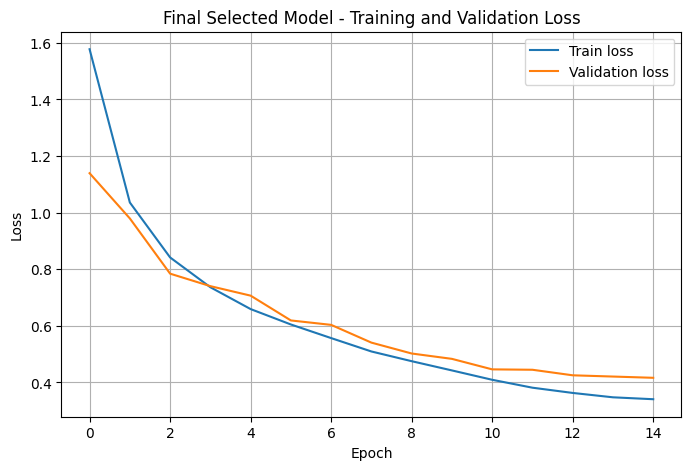

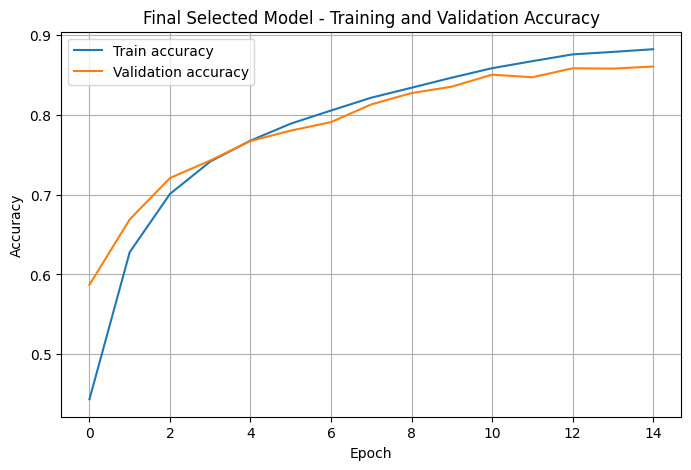

In [3]:
# ============================================================
# Stage 3 - Ablation Study for Generalization Improvement
# ============================================================
# Goal:
# Use the selected candidate after Stage 2 and examine which improvement
# components contribute to better generalization.
#
# Updated selected base model:
# C1_A4_2conv_per_block_k3_lr0.001_bs128
#
# This model is based on A4:
# - conv_channels = [32, 64, 128]
# - 2 convolutions per block
# - kernel size = 3
# - classifier hidden size = 256
# - learning rate = 0.001
# - batch size = 128
#
# The ablation study adds components gradually:
# F0: baseline
# F1: + normalization
# F2: + normalization + augmentation
# F3: + normalization + augmentation + BatchNorm
# F4: + normalization + augmentation + BatchNorm + scheduler
# F5: + normalization + augmentation + BatchNorm + scheduler + AdamW
#
# The final model is selected using validation accuracy and validation loss.
# The official test set is evaluated only once after final model selection.
# ============================================================

RUN_STAGE_3_GENERALIZATION_SEARCH = True

all_stage3_results = []

if RUN_STAGE_3_GENERALIZATION_SEARCH:

    print("\n" + "#" * 90)
    print("STAGE 3: ABLATION STUDY FOR FINAL GENERALIZATION IMPROVEMENT")
    print("#" * 90)

    stage3_epochs = 15

    # ------------------------------------------------------------
    # Updated selected model from Stage 2 / Stage 1 baseline
    # ------------------------------------------------------------
    # The selected model is C1/A4, not C4/A7.
    # It achieved the highest validation accuracy in the updated comparison.

    selected_model_config = {
        "name": "F_best_C1_A4_2conv_per_block_k3",
        "source_stage2_candidate": "C1_A4_2conv_per_block_k3_lr0.001_bs128",
        "conv_channels": [32, 64, 128],
        "convs_per_block": 2,
        "classifier_hidden_size": 256,
        "kernel_size": 3,
        "padding": 1,
        "conv_stride": 1,
        "learning_rate": 1e-3,
        "batch_size": 128
    }

    cifar10_mean = (0.4914, 0.4822, 0.4465)
    cifar10_std = (0.2470, 0.2435, 0.2616)

    # ------------------------------------------------------------
    # Transform definitions
    # ------------------------------------------------------------
    # Augmentation is used only for training.
    # Validation and test are deterministic.

    no_preprocessing_train = transforms.ToTensor()
    no_preprocessing_test = transforms.ToTensor()

    normalize_train = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(cifar10_mean, cifar10_std)
    ])

    normalize_test = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(cifar10_mean, cifar10_std)
    ])

    normalize_aug_train = transforms.Compose([
        transforms.RandomCrop(32, padding=4),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(cifar10_mean, cifar10_std)
    ])

    normalize_aug_test = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(cifar10_mean, cifar10_std)
    ])

    # ------------------------------------------------------------
    # Ablation configurations
    # ------------------------------------------------------------

    ablation_options = [
        {
            "name": "F0_baseline_no_norm_no_aug_no_bn_no_scheduler_Adam",
            "description": "Baseline selected C1/A4 architecture",
            "train_transforms": no_preprocessing_train,
            "test_transforms": no_preprocessing_test,
            "use_batchnorm": False,
            "use_scheduler": False,
            "optimizer_type": "Adam",
            "weight_decay": 0.0
        },
        {
            "name": "F1_normalize_only_Adam",
            "description": "Add input normalization",
            "train_transforms": normalize_train,
            "test_transforms": normalize_test,
            "use_batchnorm": False,
            "use_scheduler": False,
            "optimizer_type": "Adam",
            "weight_decay": 0.0
        },
        {
            "name": "F2_normalize_aug_Adam",
            "description": "Add data augmentation on top of normalization",
            "train_transforms": normalize_aug_train,
            "test_transforms": normalize_aug_test,
            "use_batchnorm": False,
            "use_scheduler": False,
            "optimizer_type": "Adam",
            "weight_decay": 0.0
        },
        {
            "name": "F3_normalize_aug_batchnorm_Adam",
            "description": "Add BatchNorm to the CNN",
            "train_transforms": normalize_aug_train,
            "test_transforms": normalize_aug_test,
            "use_batchnorm": True,
            "use_scheduler": False,
            "optimizer_type": "Adam",
            "weight_decay": 0.0
        },
        {
            "name": "F4_normalize_aug_batchnorm_cosine_Adam",
            "description": "Add CosineAnnealingLR scheduler",
            "train_transforms": normalize_aug_train,
            "test_transforms": normalize_aug_test,
            "use_batchnorm": True,
            "use_scheduler": True,
            "optimizer_type": "Adam",
            "weight_decay": 0.0
        },
        {
            "name": "F5_normalize_aug_batchnorm_cosine_AdamW",
            "description": "Replace Adam with AdamW and weight decay",
            "train_transforms": normalize_aug_train,
            "test_transforms": normalize_aug_test,
            "use_batchnorm": True,
            "use_scheduler": True,
            "optimizer_type": "AdamW",
            "weight_decay": 5e-4
        }
    ]

    # ------------------------------------------------------------
    # Run ablation experiments
    # ------------------------------------------------------------

    for ablation_config in ablation_options:

        experiment_name = (
            f'{selected_model_config["name"]}_'
            f'{ablation_config["name"]}'
        )

        print("\n" + "=" * 90)
        print("Running experiment:", experiment_name)
        print("Purpose:", ablation_config["description"])
        print("=" * 90)

        set_seed(SEED)

        current_train_dataset, current_val_dataset, _ = get_train_val_test_data(
            validation_size=5000,
            train_transforms=ablation_config["train_transforms"],
            test_transforms=ablation_config["test_transforms"]
        )

        current_train_loader, current_val_loader = create_data_loaders(
            dataset_train=current_train_dataset,
            dataset_val=current_val_dataset,
            batch_size=selected_model_config["batch_size"]
        )

        model = FlexibleCNN(
            conv_channels=selected_model_config["conv_channels"],
            convs_per_block=selected_model_config["convs_per_block"],
            classifier_hidden_size=selected_model_config["classifier_hidden_size"],
            kernel_size=selected_model_config["kernel_size"],
            padding=selected_model_config["padding"],
            conv_stride=selected_model_config["conv_stride"],
            num_class=10,
            use_batchnorm=ablation_config["use_batchnorm"]
        )

        if ablation_config["optimizer_type"] == "Adam":
            optimizer = optim.Adam(
                model.parameters(),
                lr=selected_model_config["learning_rate"],
                weight_decay=ablation_config["weight_decay"]
            )

        elif ablation_config["optimizer_type"] == "AdamW":
            optimizer = optim.AdamW(
                model.parameters(),
                lr=selected_model_config["learning_rate"],
                weight_decay=ablation_config["weight_decay"]
            )

        else:
            raise ValueError("Unsupported optimizer type.")

        if ablation_config["use_scheduler"]:
            scheduler = optim.lr_scheduler.CosineAnnealingLR(
                optimizer,
                T_max=stage3_epochs,
                eta_min=1e-5
            )
        else:
            scheduler = None

        history = train(
            model=model,
            optimizer=optimizer,
            loss_fn=loss_function,
            train_loader=current_train_loader,
            val_loader=current_val_loader,
            epochs=stage3_epochs,
            device=device,
            scheduler=scheduler
        )

        experiment_result = {
            "stage": "Stage 3",
            "name": experiment_name,
            "base_model": selected_model_config["source_stage2_candidate"],
            "description": ablation_config["description"],

            "conv_channels": selected_model_config["conv_channels"],
            "convs_per_block": selected_model_config["convs_per_block"],
            "classifier_hidden_size": selected_model_config["classifier_hidden_size"],
            "kernel_size": selected_model_config["kernel_size"],
            "padding": selected_model_config["padding"],
            "conv_stride": selected_model_config["conv_stride"],
            "learning_rate": selected_model_config["learning_rate"],
            "batch_size": selected_model_config["batch_size"],

            "use_batchnorm": ablation_config["use_batchnorm"],
            "use_scheduler": ablation_config["use_scheduler"],
            "optimizer_type": ablation_config["optimizer_type"],
            "weight_decay": ablation_config["weight_decay"],

            "final_train_loss": history["train_loss"][-1],
            "final_train_acc": history["train_acc"][-1],
            "final_val_loss": history["val_loss"][-1],
            "final_val_acc": history["val_acc"][-1],

            "best_val_loss": history["best_val_loss"],
            "best_val_acc": history["best_val_acc"],
            "best_epoch": history["best_epoch"],
            "best_model_state_dict": history["best_model_state_dict"],

            "history": history,
            "train_transforms": ablation_config["train_transforms"],
            "test_transforms": ablation_config["test_transforms"]
        }

        all_stage3_results.append(experiment_result)

        del model
        del optimizer

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    # ------------------------------------------------------------
    # Print Stage 3 summary
    # ------------------------------------------------------------

    print("\n" + "=" * 90)
    print("STAGE 3 SUMMARY: ABLATION STUDY")
    print("=" * 90)

    for result in all_stage3_results:
        print(
            result["name"],
            "| optimizer:", result["optimizer_type"],
            "| batchnorm:", result["use_batchnorm"],
            "| scheduler:", result["use_scheduler"],
            "| weight_decay:", result["weight_decay"],
            "| best epoch:", result["best_epoch"],
            "| best val loss:", round(result["best_val_loss"], 4),
            "| best val acc:", round(result["best_val_acc"], 4),
            "| final train acc:", round(result["final_train_acc"], 4),
            "| final val acc:", round(result["final_val_acc"], 4)
        )

    ranked_stage3_results = sorted(
        all_stage3_results,
        key=lambda result: (
            result["best_val_acc"],
            -result["best_val_loss"]
        ),
        reverse=True
    )

    print("\nTop Stage 3 candidates, ranked by validation accuracy:")

    for rank, result in enumerate(ranked_stage3_results, start=1):
        print(
            f"{rank}.",
            result["name"],
            "| best val acc:", round(result["best_val_acc"], 4),
            "| best val loss:", round(result["best_val_loss"], 4),
            "| best epoch:", result["best_epoch"]
        )

    # ------------------------------------------------------------
    # Select final model
    # ------------------------------------------------------------
    # Primary criterion: highest validation accuracy.
    # Tie-breaking: among models within 0.001 accuracy, choose lower validation loss.

    best_stage3_acc = ranked_stage3_results[0]["best_val_acc"]

    close_candidates = [
        result for result in ranked_stage3_results
        if best_stage3_acc - result["best_val_acc"] <= 0.001
    ]

    final_selected_result = sorted(
        close_candidates,
        key=lambda result: result["best_val_loss"]
    )[0]

    print("\n" + "=" * 90)
    print("FINAL SELECTED MODEL")
    print("=" * 90)
    print("Selected model:", final_selected_result["name"])
    print("Best validation accuracy:", round(final_selected_result["best_val_acc"], 4))
    print("Best validation loss:", round(final_selected_result["best_val_loss"], 4))
    print("Best epoch:", final_selected_result["best_epoch"])

    # ------------------------------------------------------------
    # Final test evaluation
    # ------------------------------------------------------------
    # The test set is evaluated only once after final model selection.

    print("\n" + "=" * 90)
    print("FINAL TEST SET EVALUATION")
    print("=" * 90)

    set_seed(SEED)

    _, _, final_test_dataset = get_train_val_test_data(
        validation_size=5000,
        train_transforms=final_selected_result["train_transforms"],
        test_transforms=final_selected_result["test_transforms"]
    )

    final_test_loader = DataLoader(
        dataset=final_test_dataset,
        batch_size=final_selected_result["batch_size"],
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available()
    )

    final_model = FlexibleCNN(
        conv_channels=final_selected_result["conv_channels"],
        convs_per_block=final_selected_result["convs_per_block"],
        classifier_hidden_size=final_selected_result["classifier_hidden_size"],
        kernel_size=final_selected_result["kernel_size"],
        padding=final_selected_result["padding"],
        conv_stride=final_selected_result["conv_stride"],
        num_class=10,
        use_batchnorm=final_selected_result["use_batchnorm"]
    )

    final_model.load_state_dict(final_selected_result["best_model_state_dict"])
    final_model = final_model.to(device)

    test_loss, test_acc = test(
        model=final_model,
        test_loader=final_test_loader,
        loss_fn=loss_function,
        device=device
    )

    print("Test loss:", round(test_loss, 4))
    print("Test accuracy:", round(test_acc, 4))

    final_selected_result["test_loss"] = test_loss
    final_selected_result["test_acc"] = test_acc

    # ------------------------------------------------------------
    # Plot final selected model learning curves
    # ------------------------------------------------------------

    final_history = final_selected_result["history"]

    plt.figure(figsize=(8, 5))
    plt.plot(final_history["train_loss"], label="Train loss")
    plt.plot(final_history["val_loss"], label="Validation loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Final Selected Model - Training and Validation Loss")
    plt.legend()
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(final_history["train_acc"], label="Train accuracy")
    plt.plot(final_history["val_acc"], label="Validation accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title("Final Selected Model - Training and Validation Accuracy")
    plt.legend()
    plt.grid(True)
    plt.show()

# Part 2

In [1]:
import torch
import torchvision

print("torch:", torch.__version__)
print("torchvision:", torchvision.__version__)
print("cuda available:", torch.cuda.is_available())

torch: 2.7.1+cu118
torchvision: 0.22.1+cu118
cuda available: False


In [2]:
############################################################################
# Part 2.1.a: Load AlexNet 
############################################################################

In [3]:
from torchvision.models.feature_extraction import create_feature_extractor, get_graph_node_names
from torchvision.models import alexnet, AlexNet_Weights
from PIL import Image

import torch.nn as nn
from torchvision.models import alexnet, AlexNet_Weights
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

weights = AlexNet_Weights.DEFAULT
model = alexnet(weights=weights)
model = model.to(device)
model.eval()

print(model)        # Understanding AlexNet full structure

device: cpu
AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(6, 6))
  (classifier): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=9216, out_features=4096, 

In [4]:
weights = AlexNet_Weights.DEFAULT

# The official preprocessing AlexNet expects:
preprocess_with_norm = weights.transforms()

print(preprocess_with_norm)

preprocess_without_norm = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor()])
print(preprocess_without_norm)

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
Compose(
    Resize(size=256, interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    ToTensor()
)


In [5]:
import os

image_paths = [
    "images/bird.JPEG",
    "images/dog.JPEG",
    "images/cat.JPEG",
    "images/car.JPEG",
    "images/ship.JPEG"]

image_info = [
    {"path": "images/cat.JPEG", "true_label": "Persian cat"},
    {"path": "images/dog.JPEG", "true_label": "Norfolk terrier"},
    {"path": "images/bird.JPEG", "true_label": "macaw"},
    {"path": "images/car.JPEG", "true_label": "school bus"},
    {"path": "images/ship.JPEG", "true_label": "speedboat"},]


def predict_image(image_path, preprocess, model, weights, device):
    # Open image and make sure it is RGB
    img = Image.open(image_path).convert("RGB")
    
    # Apply preprocessing
    input_tensor = preprocess(img)
    
    # Add batch dimension: [3, 224, 224] -> [1, 3, 224, 224]
    input_batch = input_tensor.unsqueeze(0).to(device)
    
    # Forward pass through AlexNet
    with torch.no_grad():
        output = model(input_batch)
    
    # Get predicted class index
    predicted_index = output.argmax(dim=1).item()
    
    # Convert index to label name
    categories = weights.meta["categories"]
    predicted_label = categories[predicted_index]
    
    return predicted_index, predicted_label

In [6]:
print("Predictions WITH normalization:")

for item in image_info:
    idx, label = predict_image(
        item["path"], 
        preprocess_with_norm, 
        model, 
        weights, 
        device)
    print(item["path"], "| true:", item["true_label"], "| predicted:", label)


print("\nPredictions WITHOUT normalization:")

for item in image_info:
    idx, label = predict_image(
        item["path"], 
        preprocess_without_norm, 
        model, 
        weights, 
        device)
    print(item["path"], "| true:", item["true_label"], "| predicted:", label)

    

Predictions WITH normalization:
images/cat.JPEG | true: Persian cat | predicted: Persian cat
images/dog.JPEG | true: Norfolk terrier | predicted: Norfolk terrier
images/bird.JPEG | true: macaw | predicted: macaw
images/car.JPEG | true: school bus | predicted: trolleybus
images/ship.JPEG | true: speedboat | predicted: speedboat

Predictions WITHOUT normalization:
images/cat.JPEG | true: Persian cat | predicted: Persian cat
images/dog.JPEG | true: Norfolk terrier | predicted: West Highland white terrier
images/bird.JPEG | true: macaw | predicted: hippopotamus
images/car.JPEG | true: school bus | predicted: passenger car
images/ship.JPEG | true: speedboat | predicted: broom


In [7]:
############################################################################
# Part 2.1.b: Changes in accuracy
############################################################################

In [8]:
# True labels for the five selected images
true_labels = ["Persian cat", "Norfolk terrier", "macaw", "school bus", "speedboat"]

# Predictions obtained with the official AlexNet normalization
pred_with_norm = ["Persian cat", "Norfolk terrier", "macaw", "trolleybus", "speedboat"]

# Predictions obtained without normalization
pred_without_norm = ["Persian cat", "West Highland white terrier", "hippopotamus", "passenger car", "broom"]

# Calculate accuracy by counting exact matches between true labels and predictions
acc_with_norm = sum(t == p for t, p in zip(true_labels, pred_with_norm)) / len(true_labels)
acc_without_norm = sum(t == p for t, p in zip(true_labels, pred_without_norm)) / len(true_labels)

# Calculate the decrease in accuracy when normalization is removed
acc_diff = acc_with_norm - acc_without_norm

print(f"Accuracy with normalization: {acc_with_norm * 100:.1f}%")
print(f"Accuracy without normalization: {acc_without_norm * 100:.1f}%")
print(f"Difference: {acc_diff * 100:.1f} percentage points")

Accuracy with normalization: 80.0%
Accuracy without normalization: 20.0%
Difference: 60.0 percentage points


In [9]:
############################################################################
# Part 2.2.a:  Visualize the weights of the first layer of AlexNet 
############################################################################

Conv1 weights shape: torch.Size([64, 3, 11, 11])


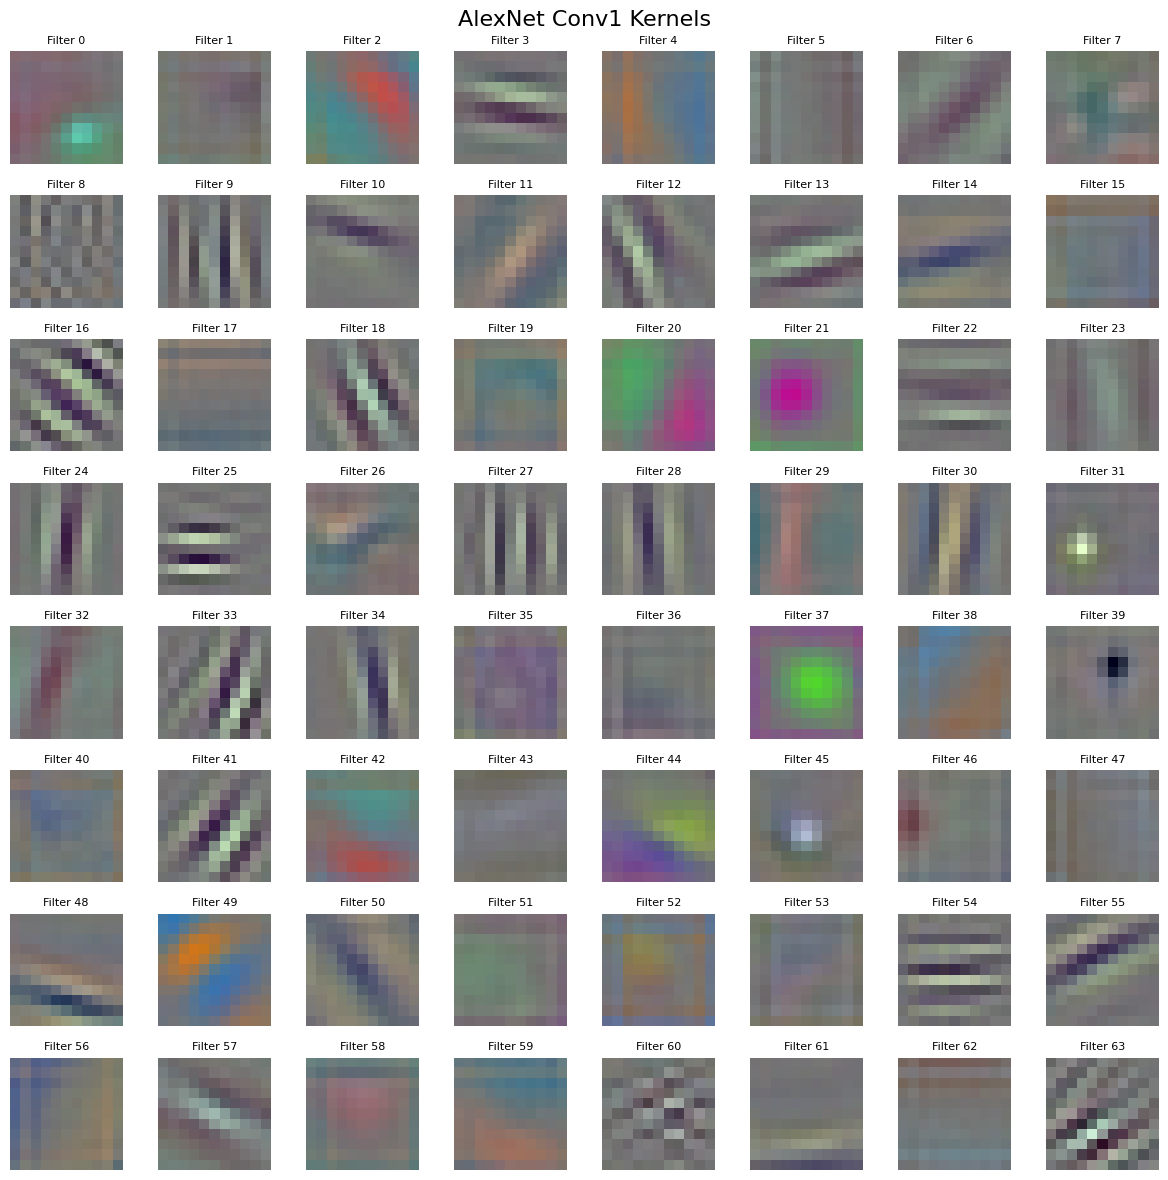

In [10]:
import matplotlib.pyplot as plt

# Get the weights of the first convolutional layer: In AlexNet, model.features[0] is the first Conv2d layer.
conv1_weights = model.features[0].weight.data.cpu()

# Expected shape: [64, 3, 11, 11]. Understanding what the tensor contains.
print("Conv1 weights shape:", conv1_weights.shape)

# Conv1 weights are not real image pixels; they can be negative or larger than 1.
# To display them with imshow as RGB images, we rescale all weights globally to [0, 1].
# This keeps all filters on the same visual scale.
w_min = conv1_weights.min()
w_max = conv1_weights.max()

# The smallest weight becomes 0, and the largest weight becomes 1.
conv1_weights_scaled = (conv1_weights - w_min) / (w_max - w_min)

# Create an 8x8 grid because AlexNet has 64 filters in the first layer.
fig, axes = plt.subplots(8, 8, figsize=(12, 12))

# Plot each of the 64 kernels as a small RGB image.
for i, ax in enumerate(axes.flat):
    # Each kernel is currently shaped [3, 11, 11] and imshow expects image shape [height, width, channels], so we change it to [11, 11, 3].
    kernel_img = conv1_weights_scaled[i].permute(1, 2, 0)
    ax.imshow(kernel_img)
    ax.axis("off")
    ax.set_title(f"Filter {i}", fontsize=8)         # Which filter we are looking at

plt.suptitle("AlexNet Conv1 Kernels", fontsize=16)
plt.tight_layout()
plt.show()

In [11]:
# Get the weights of the second convolutional layer. In AlexNet, model.features[3] is the second Conv2d layer.
conv2_weights = model.features[3].weight.data.cpu()

# We print the shape so we can describe the dimensions of the kernels.
print("Conv2 weights shape:", conv2_weights.shape)

Conv2 weights shape: torch.Size([192, 64, 5, 5])


In [12]:
############################################################################
# Part 2.2.c:  Visualize the weights of the first layer of AlexNet 
############################################################################
# The weight tensor of the second convolutional layer has dimensions [192, 64, 5, 5]. 
# This means that the layer contains 192 filters, 
# each filter receives input from 64 feature maps from the previous layer, and each spatial kernel has size 5×5.

In [13]:
############################################################################
# Part 2.2.d:  Visualize the weights of the first layer of AlexNet 
############################################################################
# The second convolutional layer cannot be visualized in the same direct way as the first convolutional layer.
# The first layer receives a 3-channel RGB image, so each kernel has three channels and can be displayed as a small RGB image. 
# In contrast, the second convolutional layer receives 64 feature maps from the previous layer. 
# Therefore, each kernel has 64 input channels rather than 3 color channels.
# Because these 64 channels do not correspond to RGB colors, a direct RGB visualization would be misleading. 
# One could visualize individual channels separately, average across channels, or reduce the 64 channels to 3 dimensions, but each of these methods loses information and does not fully represent the learned filter.

In [14]:
############################################################################
# Part 3.a: Noisy image
############################################################################

device: cpu
Image shape: torch.Size([1, 3, 224, 224])
Min pixel value: 0.45592010021209717
Max pixel value: 0.5451515913009644


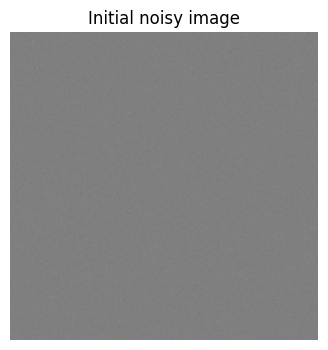

In [15]:
import torch
import matplotlib.pyplot as plt

# Use GPU if available, otherwise use CPU.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

# Create a noisy image.
# We create shape (1, 3, 224, 224), where 1 means "one image".
img = torch.normal(
    mean=0.5,
    std=0.01,
    size=(1, 3, 224, 224),
    device=device)

# Keep pixel values within the valid image range [0, 1].
img = torch.clamp(img, 0, 1)

print("Image shape:", img.shape)
print("Min pixel value:", img.min().item())
print("Max pixel value:", img.max().item())

# Convert the tensor to a format that matplotlib can display:
# from [1, 3, 224, 224] to [224, 224, 3]
img_to_show = img[0].detach().cpu().permute(1, 2, 0)

plt.figure(figsize=(4, 4))
plt.imshow(img_to_show)
plt.axis("off")
plt.title("Initial noisy image")
plt.show()

In [16]:
from torchvision.models.feature_extraction import create_feature_extractor, get_graph_node_names
from torchvision.models import alexnet, AlexNet_Weights
from PIL import Image


class FeatureExtractor(nn.Module):

    layer_dict = {
        "conv1":"features.0",
        "conv2":"features.3",
        "conv3":"features.6",
        "conv4":"features.8",
        "conv5":"features.10",
        "fc6":"classifier.1",
        "fc7":"classifier.4",
        "fc8":"classifier.6",
    }
    
    def __init__(self, required_layer="conv1"):
        super(FeatureExtractor, self).__init__()
        weights = AlexNet_Weights.DEFAULT
        model = alexnet(weights=weights)
        
        for param in model.parameters():
            param.requires_grad = False
        model.eval()

        self.required_layer = required_layer

        self.model = create_feature_extractor(model, return_nodes={FeatureExtractor.layer_dict[required_layer]: "activation"})


    def forward(self, x):
        return self.model(x)["activation"]

In [17]:
############################################################################
# Part 3.b: Gradient ascent
############################################################################

In [18]:
def tv_color_normalization(im_tensor):
    """
    Normalize the image tensor to have zero mean and unit variance according to the conventions of TorchVision ImageNet 1K models.

    args:
    im_tensor: Tensor of shape (C, H, W) or (N, C, H, W)
    """

    # We put them on the same device as the image to avoid CPU/GPU mismatch errors.
    mean = torch.tensor([0.485, 0.456, 0.406], device=im_tensor.device)
    std = torch.tensor([0.229, 0.224, 0.225], device=im_tensor.device)

    # If the tensor is 4D, it has a batch dimension: [N, C, H, W].
    if im_tensor.dim() == 4:
        mean = mean.view(1, 3, 1, 1)
        std = std.view(1, 3, 1, 1)

    # If the tensor is 3D, it is a single image: [C, H, W].
    else:
        mean = mean.view(3, 1, 1)
        std = std.view(3, 1, 1)
        
    # Normalize the tensor
    im_tensor = (im_tensor - mean) / std
    return im_tensor

In [19]:
# Instead of using AlexNet's final classification output, we create a feature extractor. This extractor returns the activation of conv1.
extractor = FeatureExtractor(required_layer="conv1").to(device)

# Set the extractor to evaluation mode because we are not training AlexNet, We only use it to compute activations.
extractor.eval()

# Enable gradient computation for the image, because the image is the thing we want to optimize.
img.requires_grad_(True)

# Normalize the image because pretrained AlexNet expects ImageNet-normalized input.
normalized_img = tv_color_normalization(img)            
activation = extractor(normalized_img)
print("Activation shape:", activation.shape)

Activation shape: torch.Size([1, 64, 55, 55])


In [20]:
# Select the first channel.
channel_idx = 0

# Find the middle row and middle column in the activation map.
center_row = activation.shape[2] // 2
center_col = activation.shape[3] // 2

# Select one scalar activation value. This is the value we want to maximize.
out = activation[0, channel_idx, center_row, center_col]

print("Center row:", center_row)
print("Center col:", center_col)
print("Initial activation:", out.item())

Center row: 27
Center col: 27
Initial activation: -0.8168588876724243


In [21]:
# Compute the gradient of this activation value with respect to the input image.
out.backward()

print("Gradient shape:", img.grad.shape)

Gradient shape: torch.Size([1, 3, 224, 224])


In [22]:
# Choose the step size for gradient ascent.
# The assignment recommends alpha > 1.
alpha = 1.2

# Choose how many optimization steps to perform.
# **The activation reached a plateau after only a few steps, 
# suggesting that additional optimization steps did not substantially improve the objective.
num_steps = 25              

# Store activation values so we can check whether optimization increases the activation.
activation_history = []

for step in range(num_steps):
    # Clear old gradients from the previous step. If we do not clear them, gradients will accumulate.
    if img.grad is not None:
        img.grad.zero_()

    # Normalize the image before feeding it to AlexNet.
    # The image itself stays in the valid pixel range [0, 1].
    normalized_img = tv_color_normalization(img)

    # Forward pass through the feature extractor to get conv1 feature maps.
    activation = extractor(normalized_img)

    # Select the central unit of the first channel. This scalar is the objective we want to maximize.
    channel_idx = 0
    out = activation[0, channel_idx, activation.shape[2] // 2, activation.shape[3] // 2]

    # Compute the gradient of the selected activation with respect to the image.
    out.backward()

    # Update the image using gradient ASCENT.
    # We add the gradient because we want to increase the activation.
    with torch.no_grad():
        img += alpha * img.grad

        # Keep image pixels within the valid range [0, 1].
        img.clamp_(0, 1)

    # Save the current activation value for monitoring.
    activation_history.append(out.item())

print("Initial activation:", activation_history[0])
print("Final activation:", activation_history[-1])

Initial activation: -0.8168588876724243
Final activation: 62.015506744384766


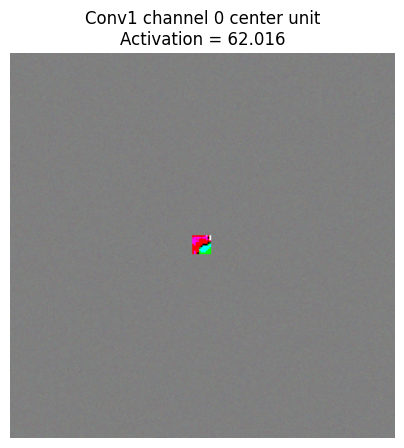

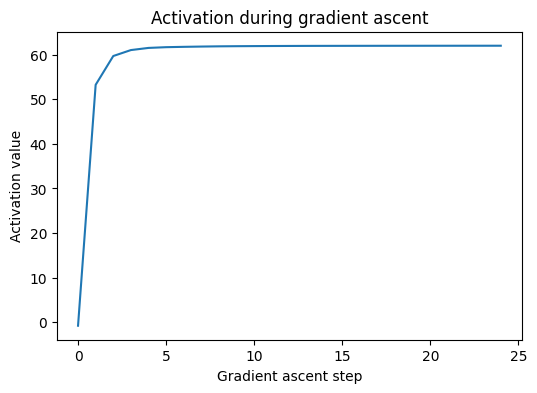

In [23]:
# Convert image from PyTorch format [1, 3, 224, 224]
# to matplotlib format [224, 224, 3].
optimized_img = img.detach().cpu().squeeze(0).permute(1, 2, 0)

plt.figure(figsize=(5, 5))
plt.imshow(optimized_img)
plt.axis("off")
plt.title(f"Conv1 channel {channel_idx} center unit\nActivation = {activation_history[-1]:.3f}")
plt.show()

plt.figure(figsize=(6, 4))
plt.plot(activation_history)
plt.xlabel("Gradient ascent step")
plt.ylabel("Activation value")
plt.title("Activation during gradient ascent")
plt.show()

In [24]:
# The optimized image contains a small localized color pattern near the center,
# while most of the image remains close to the original gray noisy background.
# This is expected because we maximized a single spatial unit in the first
# convolutional layer. A conv1 unit has a local receptive field, so only a
# small region of the input image strongly affects its activation. 


# The activation increased rapidly during the first few optimization steps
# and then reached a plateau. This suggests that the selected unit was quickly
# maximized, and additional steps provided little further improvement.

# The small central patch represents an input pattern that strongly activates the selected conv1 unit. 
# Since we optimized the central spatial unit of channel 0, only the corresponding local receptive field in the image changed substantially. 
# Therefore, the result can be interpreted as a visual pattern to which this unit is sensitive, 
# although it is not necessarily the unique global maximum because the result depends on the initialization, step size, number of optimization steps, and clipping to the valid pixel range.


In [25]:
############################################################################
# Part 3.c: Activation maximization for other conv1 channels
############################################################################

In [26]:
# Each channel corresponds to a different filter in the first convolutional layer.
channels_to_test = [0, 20, 33, 54]

# Optimization settings:
alpha = 1.2                 # Alpha controls how much we change the image pixels at each optimization step.
num_steps = 25

# Store the optimized images and activation values for later visualization.
results_3c = []

# Create one feature extractor for conv1.
extractor = FeatureExtractor(required_layer="conv1").to(device)
extractor.eval()

for channel_idx in channels_to_test:
    # Create a new noisy image for this channel. Start from scratch so each channel is optimized independently.
    img = torch.normal(
        mean=0.5,
        std=0.01,
        size=(1, 3, 224, 224),
        device=device)

    # Keep the initial image in the valid pixel range [0, 1].
    img = torch.clamp(img, 0, 1)

    # Enable gradients for the image because we optimize the image itself.
    img.requires_grad_(True)

    # Store activation values during optimization.
    activation_history = []

    for step in range(num_steps):
        # Clear old gradients so they do not accumulate across steps.
        if img.grad is not None:
            img.grad.zero_()

        # Normalize the image before feeding it to pretrained AlexNet.
        normalized_img = tv_color_normalization(img)

        # Forward pass: get conv1 activation maps.
        activation = extractor(normalized_img)

        # Choose the middle spatial unit. The location is fixed so differences come mainly from the channel/filter.
        center_row = activation.shape[2] // 2
        center_col = activation.shape[3] // 2

        # Select the unit we want to maximize: first image in batch, selected channel, center row, center column.
        out = activation[0, channel_idx, center_row, center_col]

        # Compute gradients of this activation with respect to the input image.
        out.backward()

        # Gradient ASCENT: add the gradient to increase the activation.
        with torch.no_grad():
            img += alpha * img.grad

            # Keep pixel values within the valid image range [0, 1].
            img.clamp_(0, 1)

        # Save activation value for monitoring.
        activation_history.append(out.item())

    # Convert the final optimized image to matplotlib format.
    optimized_img = img.detach().cpu().squeeze(0).permute(1, 2, 0)

    # Save the result for this channel.
    results_3c.append({
        "channel": channel_idx,
        "row": center_row,
        "col": center_col,
        "image": optimized_img,
        "final_activation": activation_history[-1],
        "activation_history": activation_history})

    print(
        f"Channel {channel_idx} | "
        f"unit=({center_row}, {center_col}) | "
        f"final activation={activation_history[-1]:.3f}")

Channel 0 | unit=(27, 27) | final activation=62.016
Channel 20 | unit=(27, 27) | final activation=103.992
Channel 33 | unit=(27, 27) | final activation=100.018
Channel 54 | unit=(27, 27) | final activation=102.525


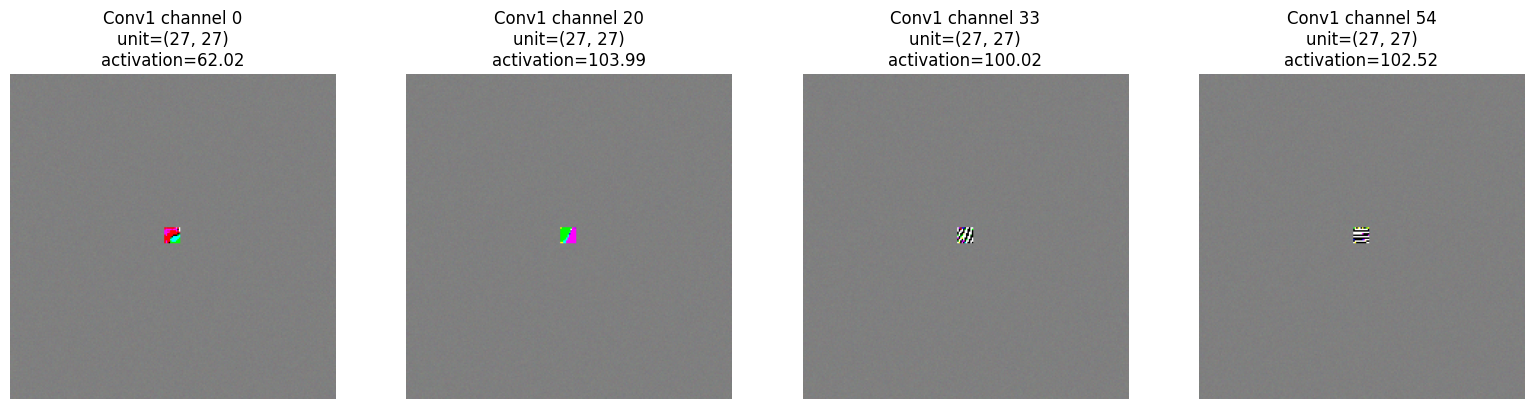

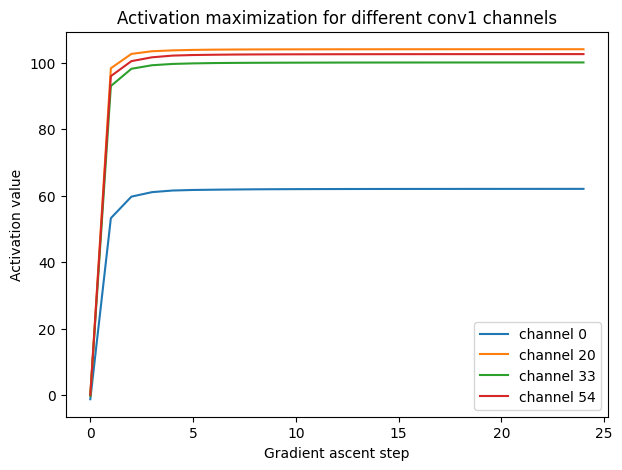

In [27]:
# Plot optimized images
fig, axes = plt.subplots(1, len(results_3c), figsize=(4 * len(results_3c), 4))

for ax, result in zip(axes, results_3c):
    ax.imshow(result["image"])
    ax.axis("off")
    ax.set_title(
        f"Conv1 channel {result['channel']}\n"
        f"unit=({result['row']}, {result['col']})\n"
        f"activation={result['final_activation']:.2f}")

plt.tight_layout()
plt.show()


# Plot activation histories
plt.figure(figsize=(7, 5))
for result in results_3c:
    plt.plot(
        result["activation_history"],
        label=f"channel {result['channel']}")

plt.xlabel("Gradient ascent step")
plt.ylabel("Activation value")
plt.title("Activation maximization for different conv1 channels")
plt.legend()
plt.show()

In [28]:
############################################################################
# Part 3.d: Activation maximization function for different AlexNet layers
############################################################################

In [29]:
layers_to_test = ["conv1", "conv2", "conv3", "conv4", "conv5", "fc6", "fc7", "fc8"]

#    Generate an activation maximization image for a selected AlexNet layer.
def activation_maximization_for_layer(layer_name, alpha=1.2, num_steps=25):
    # Create a feature extractor for the requested layer.
    extractor = FeatureExtractor(required_layer=layer_name).to(device)
    extractor.eval()

    # Create a fresh noisy image. Start from scratch for each layer so the results are independent.
    img = torch.normal(
        mean=0.5,
        std=0.01,
        size=(1, 3, 224, 224),
        device=device)

    # Keep the initial image inside the valid pixel range [0, 1].
    img = torch.clamp(img, 0, 1)

    # Enable gradients for the image because we optimize the image itself.
    img.requires_grad_(True)

    # Store activation values during optimization.
    activation_history = []

    for step in range(num_steps):
        # Clear old gradients so they do not accumulate across steps.
        if img.grad is not None:
            img.grad.zero_()

        # Normalize the image before feeding it to pretrained AlexNet.
        normalized_img = tv_color_normalization(img)

        # Get the activation of the selected layer.
        activation = extractor(normalized_img)

        # For convolutional layers, we maximize the central unit of channel 0. Shape [batch, channels, height, width].
        if layer_name.startswith("conv"):
            center_row = activation.shape[2] // 2
            center_col = activation.shape[3] // 2

            out = activation[0, 0, center_row, center_col]

        # For fully connected layers, we maximize unit 0. Shape [batch, units].
        else:
            out = activation[0, 0]

        # Compute the gradient of the selected activation with respect to the image.
        out.backward()

        # Gradient ASCENT: add the gradient to increase the selected activation.
        with torch.no_grad():
            img += alpha * img.grad

            # Keep pixel values in the valid image range [0, 1].
            img.clamp_(0, 1)

        # Save activation value for monitoring.
        activation_history.append(out.item())

    # Convert image from PyTorch format [1, 3, 224, 224] to matplotlib format [224, 224, 3].
    final_img = img.detach().cpu().squeeze(0).permute(1, 2, 0)

    return final_img, activation_history

In [30]:
# Optimization settings:
alpha = 1.2         # Alpha controls how much we change the image pixels at each optimization step.
num_steps = 25

# Store all results.
results_3d = []

for layer_name in layers_to_test:
    final_img, activation_history = activation_maximization_for_layer(
        layer_name=layer_name,
        alpha=alpha,
        num_steps=num_steps)

    results_3d.append({
        "layer": layer_name,
        "image": final_img,
        "activation_history": activation_history,
        "final_activation": activation_history[-1]})

    print(f"{layer_name} final activation: {activation_history[-1]:.3f}")

conv1 final activation: 62.015
conv2 final activation: 258.356
conv3 final activation: 568.339
conv4 final activation: 340.311
conv5 final activation: 416.625
fc6 final activation: 804.121
fc7 final activation: 799.834
fc8 final activation: 705.704


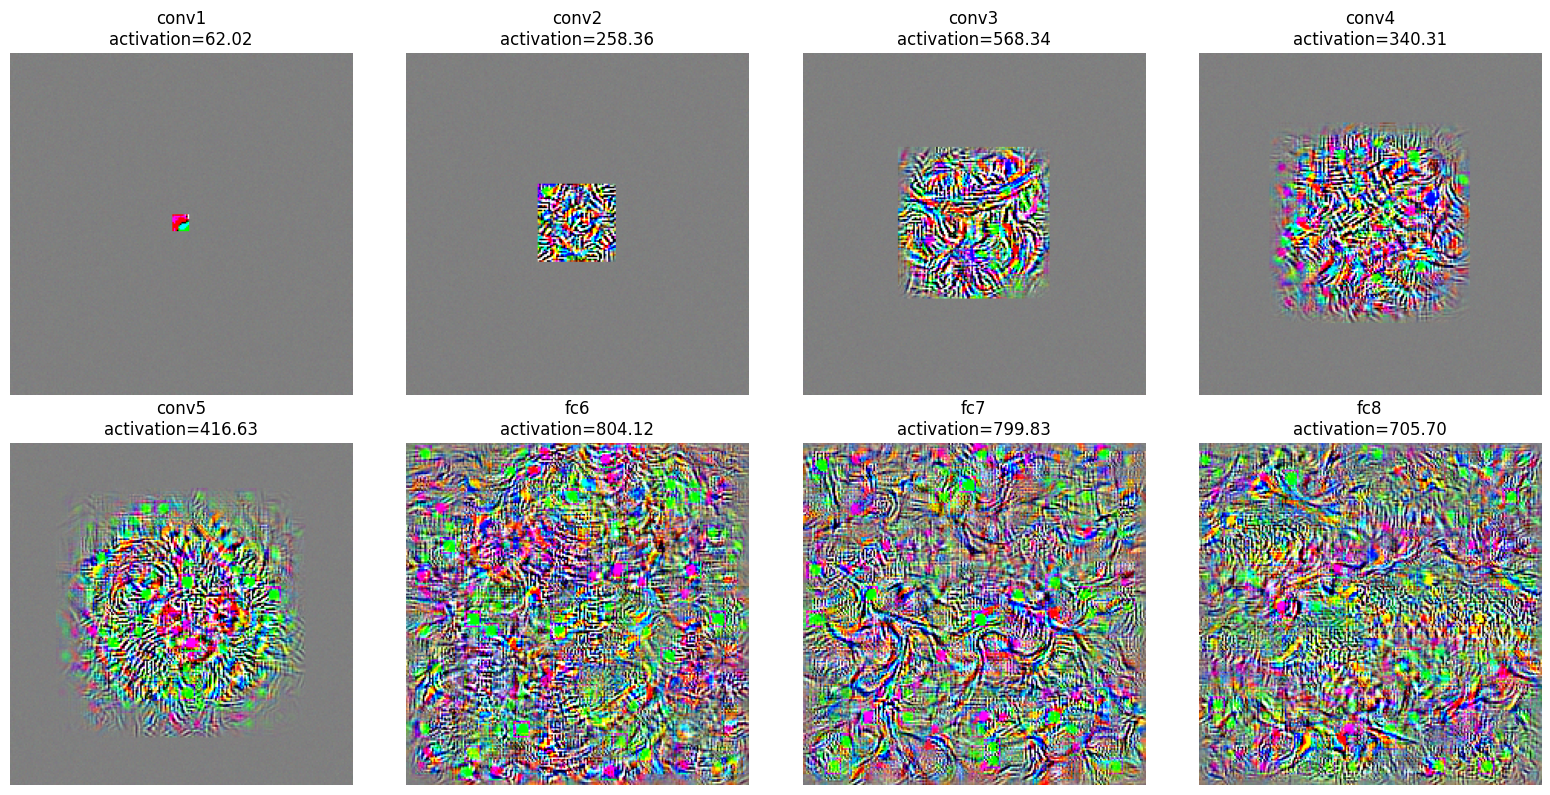

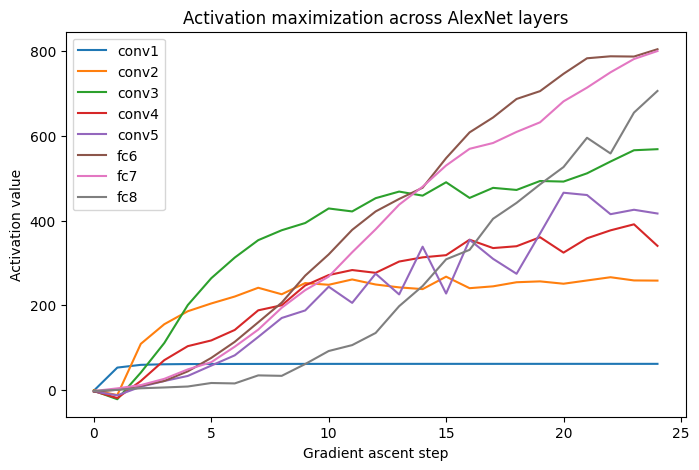

In [31]:
# Plot activation maximization images
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, result in zip(axes.flat, results_3d):
    ax.imshow(result["image"])
    ax.axis("off")
    ax.set_title(
        f"{result['layer']}\n"
        f"activation={result['final_activation']:.2f}")

plt.tight_layout()
plt.show()

# Plot activation histories
plt.figure(figsize=(8, 5))
for result in results_3d:
    plt.plot(
        result["activation_history"],
        label=result["layer"])

plt.xlabel("Gradient ascent step")
plt.ylabel("Activation value")
plt.title("Activation maximization across AlexNet layers")
plt.legend()
plt.show()

In [32]:
############################################################################
# Part 4: Activation maximization for post-softmax class probability
############################################################################

In [33]:
# Get ImageNet category names from the pretrained AlexNet weights.
categories = weights.meta["categories"]

# Choose a target class.
target_class_name = "macaw"

# Find the index of the target class.
target_idx = categories.index(target_class_name)

print("Target class:", target_class_name)
print("Target index:", target_idx)

Target class: macaw
Target index: 88


In [34]:
# Optimization settings:
alpha = 1.2
num_steps = 100

# Create a fresh noisy image.
img = torch.normal(
    mean=0.5,
    std=0.01,
    size=(1, 3, 224, 224),
    device=device)

# Keep image pixels in the valid range [0, 1].
img = torch.clamp(img, 0, 1)

# Enable gradients for the image because we optimize the image itself.
img.requires_grad_(True)

# Make sure the model is in evaluation mode.
model.eval()

# Freeze model parameters because We optimize only the image, not the model weights.
for param in model.parameters():
    param.requires_grad = False

# Store probability values during optimization.
probability_history = []

for step in range(num_steps):
    # Clear old gradients so they do not accumulate.
    if img.grad is not None:
        img.grad.zero_()

    # Normalize image before feeding it to pretrained AlexNet.
    normalized_img = tv_color_normalization(img)

    # Forward pass through AlexNet.
    logits = model(normalized_img)

    # Convert logits to post-softmax probabilities.
    probs = torch.softmax(logits, dim=1)

    # Select the probability of the target class.
    target_prob = probs[0, target_idx]

    # This is the objective we want to maximize.
    out = target_prob

    # Compute gradient of the target probability with respect to the image.
    out.backward()

    # Gradient ASCENT: update the image to increase the target probability.
    with torch.no_grad():
        img += alpha * img.grad

        # Keep image values valid as pixel intensities.
        img.clamp_(0, 1)

    # Save current target probability.
    probability_history.append(target_prob.item())

print("Initial target probability:", probability_history[0])
print("Final target probability:", probability_history[-1])

Initial target probability: 0.0010917377658188343
Final target probability: 0.9987825751304626


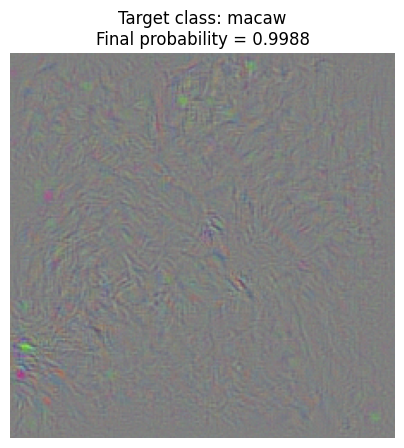

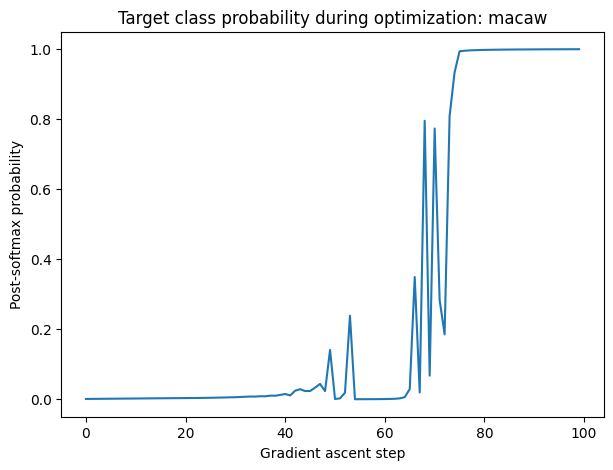

In [35]:
# Show optimized image
optimized_img = img.detach().cpu().squeeze(0).permute(1, 2, 0)
plt.figure(figsize=(5, 5))
plt.imshow(optimized_img)
plt.axis("off")
plt.title(
    f"Target class: {target_class_name}\n"
    f"Final probability = {probability_history[-1]:.4f}")
plt.show()

# Plot target class probability

plt.figure(figsize=(7, 5))
plt.plot(probability_history)
plt.xlabel("Gradient ascent step")
plt.ylabel("Post-softmax probability")
plt.title(f"Target class probability during optimization: {target_class_name}")
plt.show()

In [36]:
# Check final prediction
with torch.no_grad():
    normalized_img = tv_color_normalization(img)
    logits = model(normalized_img)
    probs = torch.softmax(logits, dim=1)

# Get top 5 predicted classes.
top_probs, top_indices = torch.topk(probs[0], k=5)

print("Top-5 predictions after optimization:")
for prob, idx in zip(top_probs, top_indices):
    print(f"{categories[idx.item()]}: {prob.item():.4f}")

print()
print(f"Target class: {target_class_name}")
print(f"Target probability: {probs[0, target_idx].item():.4f}")

Top-5 predictions after optimization:
macaw: 0.9988
lorikeet: 0.0003
European gallinule: 0.0001
umbrella: 0.0001
cock: 0.0001

Target class: macaw
Target probability: 0.9988


In [37]:
############################################################################
# Part 5: 
############################################################################

In [38]:
# We use a real image from one category as the initialization image. The "ship" image, the speedboat.
start_image_path = "images/ship.JPEG"

# This preprocessing prepares the image for optimization:
# resize + crop + convert to tensor, but WITHOUT ImageNet normalization.
# We will apply normalization inside the optimization loop.
preprocess_real_image = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor()
])

# Load the real image and convert it to RGB.
start_pil = Image.open(start_image_path).convert("RGB")

# Convert the image to a tensor in the range [0, 1].
img = preprocess_real_image(start_pil).unsqueeze(0).to(device)

# Enable gradients for the image because we will optimize the image itself.
img.requires_grad_(True)

print("Starting image shape:", img.shape)
print("Min pixel value:", img.min().item())
print("Max pixel value:", img.max().item())

Starting image shape: torch.Size([1, 3, 224, 224])
Min pixel value: 0.0
Max pixel value: 0.9019607901573181


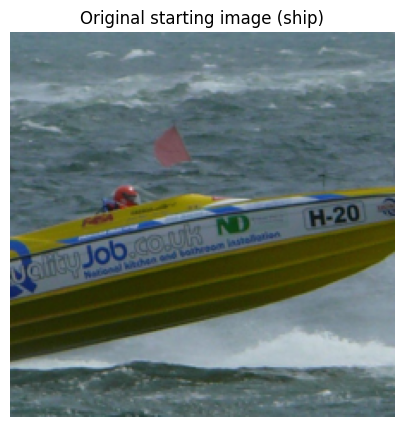

Target class: Norfolk terrier
Target index: 185


In [39]:
# Show the original starting image
original_img_to_show = img.detach().cpu().squeeze(0).permute(1, 2, 0)
plt.figure(figsize=(5, 5))
plt.imshow(original_img_to_show)
plt.axis("off")
plt.title("Original starting image (ship)")
plt.show()

# Target class
# Get ImageNet category names from the pretrained AlexNet weights.
categories = weights.meta["categories"]

# Choose a target class different from the original category.
target_class_name = "Norfolk terrier"

# Find the class index.
target_idx = categories.index(target_class_name)

print("Target class:", target_class_name)
print("Target index:", target_idx)

# Start: ship image ("speedboat")
# Target: dog class ("Norfolk terrier")
# Goal: increase the probability of "dog"

In [40]:
# Helper function to reload the original starting image.
# This is important because each optimization attempt should start from the same real image.
def load_start_image():
    start_pil = Image.open(start_image_path).convert("RGB")
    img = preprocess_real_image(start_pil).unsqueeze(0).to(device)
    img.requires_grad_(True)
    return img

In [41]:
# Check initial prediction of AlexNet before optimization
with torch.no_grad():
    normalized_img = tv_color_normalization(img)
    # AlexNet receives the image and returns logits with shape [1, 1000].
    # The model outputs logits, which are raw class scores before softmax.
    logits = model(normalized_img)
    # Convert the 1000 logits into 1000 probabilities.
    probs = torch.softmax(logits, dim=1)
# The probability that AlexNet assigns to the target class before optimization.
initial_target_prob = probs[0, target_idx].item()
initial_pred_idx = probs.argmax(dim=1).item()
initial_pred_label = categories[initial_pred_idx]

print("Initial top prediction:", initial_pred_label)
print(f"Initial probability of target class ({target_class_name}): {initial_target_prob:.6f}")

Initial top prediction: speedboat
Initial probability of target class (Norfolk terrier): 0.000000


In [42]:
# ***
# First, we tried to maximize the post-softmax probability of the target class directly.
# However, the target probability stayed extremely close to zero, probably because the
# starting image belonged to a very different class and the softmax gradient was too weak.
# Therefore, we follow the assignment suggestion and maximize the corresponding
# pre-softmax logit instead. We still report the final post-softmax probability.

In [43]:
############################################################################
# Attempt 1: Directly maximize post-softmax probability
############################################################################

# Load the original ship image again for this attempt.
img_prob = load_start_image()

# Optimization settings:
alpha_prob = 1.2
num_steps_prob = 100

# Make sure AlexNet is in evaluation mode.
model.eval()

# Freeze model parameters because we optimize only the image, not the model weights.
for param in model.parameters():
    param.requires_grad = False

# Store target class probabilities during optimization.
probability_history_prob = []

for step in range(num_steps_prob):
    # Clear old gradients so they do not accumulate across iterations.
    if img_prob.grad is not None:
        img_prob.grad.zero_()

    # Normalize the image before feeding it to pretrained AlexNet.
    normalized_img_prob = tv_color_normalization(img_prob)

    # AlexNet outputs logits, which are raw class scores before softmax.
    logits_prob = model(normalized_img_prob)

    # Convert logits to post-softmax probabilities.
    probs_prob = torch.softmax(logits_prob, dim=1)

    # Select the probability of the target class.
    target_prob_prob = probs_prob[0, target_idx]

    # Objective: directly maximize the target class probability.
    out_prob = target_prob_prob

    # Compute gradients of the target probability with respect to the image.
    out_prob.backward()

    # Gradient ASCENT: update the image to increase the target probability.
    with torch.no_grad():
        img_prob += alpha_prob * img_prob.grad
        img_prob.clamp_(0, 1)

    # Save current target probability.
    probability_history_prob.append(target_prob_prob.item())

# Save final image and probability for this attempt.
final_img_prob = img_prob.detach().cpu().squeeze(0).permute(1, 2, 0)
final_prob_direct = probability_history_prob[-1]

print("Attempt 1: Direct probability maximization")
print(f"Initial target probability: {probability_history_prob[0]:.12f}")
print(f"Final target probability: {final_prob_direct:.12f}")
print(f"Initial target probability scientific: {probability_history_prob[0]:.3e}")
print(f"Final target probability scientific: {final_prob_direct:.3e}")

Attempt 1: Direct probability maximization
Initial target probability: 0.000000006438
Final target probability: 0.000000006438
Initial target probability scientific: 6.438e-09
Final target probability scientific: 6.438e-09


In [44]:
############################################################################
# Attempt 2: Maximize pre-softmax target logit
############################################################################

# Load the original ship image again for this attempt.
img_logit = load_start_image()

# Optimization settings.
alpha_logit = 1.2
num_steps_logit = 100

# Store target class probabilities and logits during optimization.
probability_history_logit = []
logit_history_logit = []

for step in range(num_steps_logit):
    # Clear old gradients so they do not accumulate across iterations.
    if img_logit.grad is not None:
        img_logit.grad.zero_()

    # Normalize the image before feeding it to pretrained AlexNet.
    normalized_img_logit = tv_color_normalization(img_logit)

    # AlexNet outputs logits, which are raw class scores before softmax.
    logits_logit = model(normalized_img_logit)

    # Convert logits to post-softmax probabilities for monitoring.
    probs_logit = torch.softmax(logits_logit, dim=1)

    # Select the target class probability for reporting.
    target_prob_logit = probs_logit[0, target_idx]

    # Select the target class logit.
    # We optimize the logit because it often gives stronger gradients than post-softmax probability.
    target_logit_logit = logits_logit[0, target_idx]

    # Objective: maximize the target class logit.
    out_logit = target_logit_logit

    # Compute gradients of the target logit with respect to the image.
    out_logit.backward()

    # Gradient ASCENT: update the image to increase the target class logit.
    with torch.no_grad():
        img_logit += alpha_logit * img_logit.grad
        img_logit.clamp_(0, 1)

    # Save values for monitoring.
    probability_history_logit.append(target_prob_logit.item())
    logit_history_logit.append(target_logit_logit.item())

# Save final image and probability for this attempt.
final_img_logit = img_logit.detach().cpu().squeeze(0).permute(1, 2, 0)
final_prob_logit = probability_history_logit[-1]

print("Attempt 2: Logit maximization")
print(f"Initial target probability: {probability_history_logit[0]:.12f}")
print(f"Final target probability: {final_prob_logit:.12f}")
print(f"Initial target probability scientific: {probability_history_logit[0]:.3e}")
print(f"Final target probability scientific: {final_prob_logit:.3e}")
print(f"Initial target logit: {logit_history_logit[0]:.3f}")
print(f"Final target logit: {logit_history_logit[-1]:.3f}")

Attempt 2: Logit maximization
Initial target probability: 0.000000006438
Final target probability: 1.000000000000
Initial target probability scientific: 6.438e-09
Final target probability scientific: 1.000e+00
Initial target logit: -0.942
Final target logit: 699.263


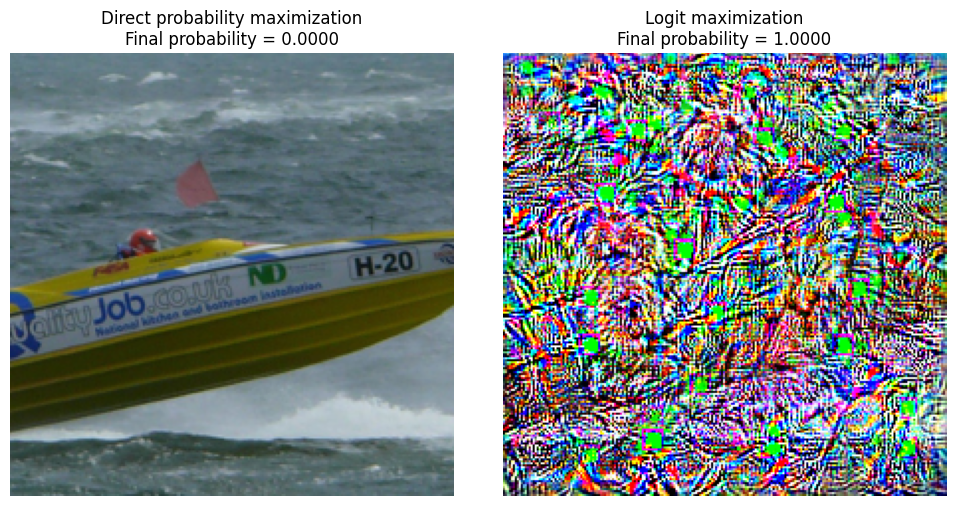

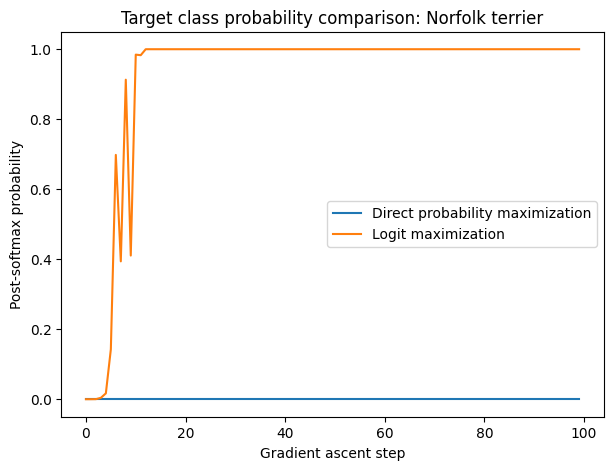

In [45]:
# Compare optimized images

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(final_img_prob)
axes[0].axis("off")
axes[0].set_title(
    f"Direct probability maximization\n"
    f"Final probability = {final_prob_direct:.4f}")
axes[1].imshow(final_img_logit)
axes[1].axis("off")
axes[1].set_title(
    f"Logit maximization\n"
    f"Final probability = {final_prob_logit:.4f}")
plt.tight_layout()
plt.show()

# Compare target probability during optimization
plt.figure(figsize=(7, 5))
plt.plot(
    probability_history_prob,
    label="Direct probability maximization")
plt.plot(
    probability_history_logit,
    label="Logit maximization")
plt.xlabel("Gradient ascent step")
plt.ylabel("Post-softmax probability")
plt.title(f"Target class probability comparison: {target_class_name}")
plt.legend()
plt.show()

In [46]:
# Check final predictions after logit maximization (The one with better results)
with torch.no_grad():
    normalized_img_logit = tv_color_normalization(img_logit)
    logits_logit = model(normalized_img_logit)
    probs_logit = torch.softmax(logits_logit, dim=1)

# Get top-5 predictions after optimization.
top_probs, top_indices = torch.topk(probs_logit[0], k=5)
print("Top-5 predictions after logit maximization:")
for prob, idx in zip(top_probs, top_indices):
    print(f"{categories[idx.item()]}: {prob.item():.4f}")

print()
print(f"Target class: {target_class_name}")
print(f"Target probability: {probs_logit[0, target_idx].item():.4f}")

Top-5 predictions after logit maximization:
Norfolk terrier: 1.0000
goldfish: 0.0000
tiger shark: 0.0000
hammerhead: 0.0000
tench: 0.0000

Target class: Norfolk terrier
Target probability: 1.0000
